In [ ]:
from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get("llama-benchmark"))

In [ ]:
import torch
from transformers import AutoConfig, AutoModelForCausalLM

model_name = "meta-llama/Llama-3.2-3B-Instruct"

config = AutoConfig.from_pretrained(model_name)

config.num_key_value_heads = 24

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    config=config,
    torch_dtype=torch.bfloat16,
    device_map="cuda",
    ignore_mismatched_sizes=True
)

print("Parameter dtype:", next(model.parameters()).dtype)
print("KV heads:", model.config.num_key_value_heads)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 3), "GiB")

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

[transformers] LlamaForCausalLM LOAD REPORT from: meta-llama/Llama-3.2-3B-Instruct
Key                                           | Status   |                                                                                               
----------------------------------------------+----------+-----------------------------------------------------------------------------------------------
model.layers.{0...27}.self_attn.v_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1024, 3072]) vs model:torch.Size([3072, 3072])
model.layers.{0...27}.self_attn.k_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1024, 3072]) vs model:torch.Size([3072, 3072])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Parameter dtype: torch.bfloat16
KV heads: 24
GPU memory allocated: 6.64 GiB


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

In [ ]:
prompt = "The cat sat on the "

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100
    )

print(tokenizer.decode(outputs[0], skip_special_tokens=True))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


The cat sat on the  proph attentive."),ecedecedassistassistassist wis wisanton affperc proph stre strepercpercpercpercpercpercpercanton riêngpercperc aff riêngecedperc aff layeredmonitor stageassistassistassistassistplate stageecedpercperc dilig diligaging Country stageanton riêngagingecedeced aff affassistassistassist OV OV fastestperc stage stage stageassistassistpercCRC traveling travelingecedpercperc stageVC VC riêng riêng riêngeced riêngplateancancVC layered OVassistalongperc riêng riêngassistopup riêng riêng riêng riêng


In [ ]:
import time
import matplotlib.pyplot as plt

sequence_lengths = [32, 64, 128, 256, 512, 1024, 2048, 4096, 8192]

latencies = []

# 10 trials to try accounting for some of the measurement noise
for length in sequence_lengths:

    trial_latencies = []

    for trial in range(3):

        with torch.no_grad():

            prefill = model(**inputs, use_cache=True)
            past_key_values = prefill.past_key_values
            next_token = prefill.logits[:, -1, :].argmax(dim=-1, keepdim=True)
            attention_mask = inputs["attention_mask"]

            step_latencies = []

            for i in range(length - 1):

                attention_mask = torch.cat(
                    [attention_mask, torch.ones_like(attention_mask[:, :1])],
                    dim=1
                )

                if torch.cuda.is_available():
                    torch.cuda.synchronize()

                start = time.perf_counter()

                outputs = model(
                    input_ids=next_token,
                    attention_mask=attention_mask,
                    past_key_values=past_key_values,
                    use_cache=True
                )

                if torch.cuda.is_available():
                    torch.cuda.synchronize()

                end = time.perf_counter()

                step_latencies.append(end - start)

                past_key_values = outputs.past_key_values
                next_token = outputs.logits[:, -1, :].argmax(dim=-1, keepdim=True)

        elapsed = sum(step_latencies)
        decode_latency = (elapsed / len(step_latencies)) * 1000

        trial_latencies.append(decode_latency)

    average_latency = sum(trial_latencies) / len(trial_latencies)
    latencies.append(average_latency)

    print(f"{length} tokens: {average_latency:.3f} ms/token")

32 tokens: 46.093 ms/token
64 tokens: 42.625 ms/token
128 tokens: 45.684 ms/token
256 tokens: 47.380 ms/token
512 tokens: 44.048 ms/token
1024 tokens: 45.875 ms/token
2048 tokens: 51.084 ms/token
4096 tokens: 64.020 ms/token
8192 tokens: 91.441 ms/token


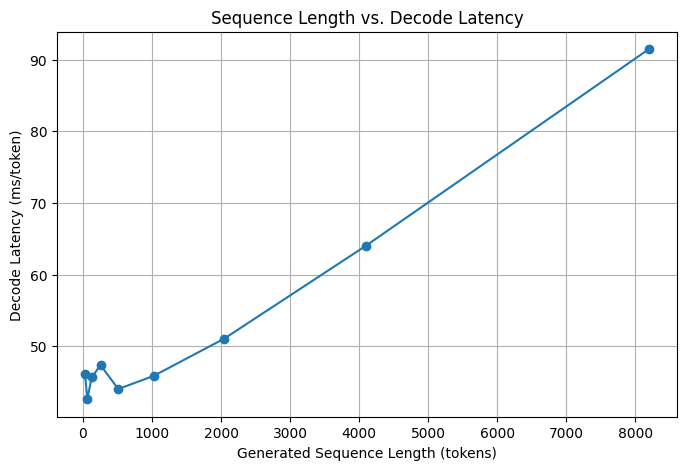

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    latencies,
    marker="o"
)

plt.xlabel("Generated Sequence Length (tokens)")
plt.ylabel("Decode Latency (ms/token)")
plt.title("Sequence Length vs. Decode Latency")
plt.grid(True)

plt.show()

In [ ]:
num_params = model.num_parameters()

num_layers = model.config.num_hidden_layers
hidden_size = model.config.hidden_size
prompt_length = inputs["input_ids"].shape[1]

compute = []

for length in sequence_lengths:

    #O(N)
    model_flops = 2 * num_params * length

    #O(N^2), but component is smaller than parameter component, so graph will prob stay relatively linear for the tested range
    attention_flops = (
        4 * num_layers * hidden_size *
        (length * prompt_length + length * (length + 1) / 2)
    )

    estimated_flops = model_flops + attention_flops

    compute.append(estimated_flops)

    print(
        f"{length} tokens: "
        f"{estimated_flops:.3e} FLOPs"
    )

32 tokens: 2.284e+11 FLOPs
64 tokens: 4.572e+11 FLOPs
128 tokens: 9.158e+11 FLOPs
256 tokens: 1.837e+12 FLOPs
512 tokens: 3.697e+12 FLOPs
1024 tokens: 7.484e+12 FLOPs
2048 tokens: 1.533e+13 FLOPs
4096 tokens: 3.210e+13 FLOPs
8192 tokens: 6.998e+13 FLOPs


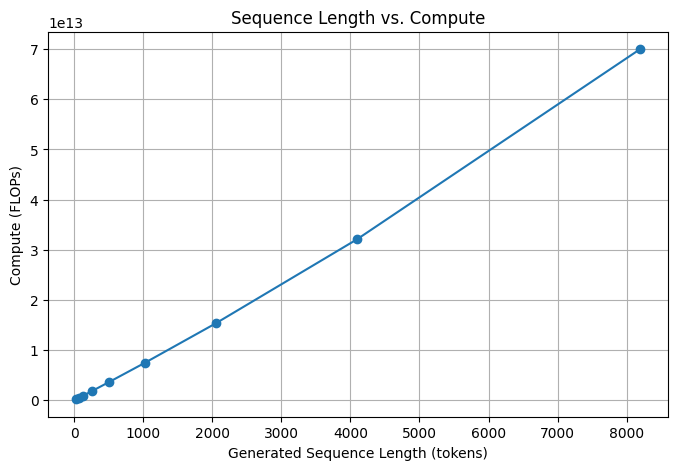

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    compute,
    marker="o"
)

plt.xlabel("Generated Sequence Length (tokens)")
plt.ylabel("Compute (FLOPs)")
plt.title("Sequence Length vs. Compute")
plt.ticklabel_format(
    axis="y",
    style="sci",
    scilimits=(0, 0)
)

plt.grid(True)
plt.show()

In [ ]:
num_layers = model.config.num_hidden_layers
num_kv_heads = model.config.num_key_value_heads
head_dim = model.config.head_dim
bytes_per_element = model.dtype.itemsize

prompt_length = inputs["input_ids"].shape[1]

memory = []

for length in sequence_lengths:

    total_tokens = prompt_length + length

    memory_bytes = (
        2
        * num_layers
        * num_kv_heads
        * head_dim
        * total_tokens
        * bytes_per_element
    )

    memory_mib = memory_bytes / (1024 ** 2)

    memory.append(memory_mib)

    print(f"{total_tokens} cached tokens: {memory_mib:.3f} MiB")

39 cached tokens: 12.797 MiB
71 cached tokens: 23.297 MiB
135 cached tokens: 44.297 MiB
263 cached tokens: 86.297 MiB
519 cached tokens: 170.297 MiB
1031 cached tokens: 338.297 MiB
2055 cached tokens: 674.297 MiB
4103 cached tokens: 1346.297 MiB
8199 cached tokens: 2690.297 MiB


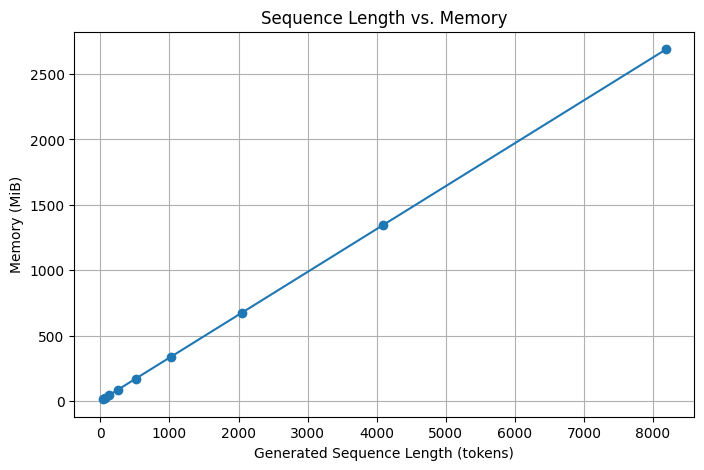

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    memory,
    marker="o"
)

plt.xlabel("Generated Sequence Length (tokens)")
plt.ylabel("Memory (MiB)")
plt.title("Sequence Length vs. Memory")
plt.grid(True)

plt.show()